# 제12장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch12


## 12.11 Attention 점수·정규화·가중합의 수치 검증

QKᵀ 점수·차원 스케일링·행별 Softmax·V 가중합을 작은 행렬로 직접 검증한다.

왼쪽 한 행은 질의 하나의 키 4개에 대한 가중치다. 오른쪽은 키 번호가 아니라 V의 출력 차원 2개다.

주의: 임베딩을 훈련하지 않았으며 실제 문장의 의미나 설명 가능한 중요도라고 주장하지 않는다. 인과 마스크도 없는 예다.

In [2]:
%run sec_11_attention.py

{
  "Q_shape": [
    3,
    2
  ],
  "K_shape": [
    4,
    2
  ],
  "V_shape": [
    4,
    2
  ],
  "row_sums": [
    1.0,
    0.9999999999999999,
    1.0
  ],
  "output_shape": [
    3,
    2
  ]
}


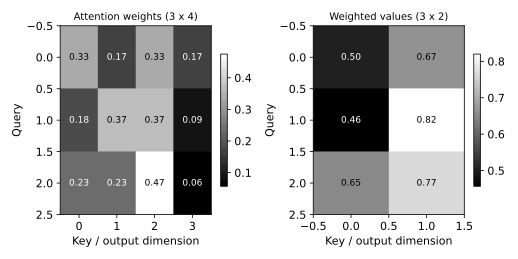

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/attention.svg"))

### 확인 과제

첫 행의 가중치 4개를 손으로 더하고 첫 출력 벡터를 V의 가중합으로 재계산한다.

## 12.12 한국어 문서 TF-IDF 검색과 근거 프롬프트

질문과 문서의 검색 점수를 계산하고 근거 문서를 식별자로 연결한 프롬프트를 만든다.

막대는 코사인 유사도이며 답변의 사실성 확률이 아니다. 동점은 원래 문서 순서로 정렬하여 재현성을 유지한다.

주의: 생성 모델은 호출하지 않는다. 프롬프트 저장까지 검증했으며 RAG 답변 생성·환각 감소 성능을 측정한 것이 아니다.

In [4]:
%run sec_12_retrieval.py

{
  "documents": 60,
  "question": "데이터 전처리와 결측값 처리 방법은?",
  "top_ids": [
    "DOC000",
    "DOC013",
    "DOC026",
    "DOC039",
    "DOC052"
  ],
  "top_scores": [
    0.20643015755249697,
    0.20643015755249697,
    0.20643015755249697,
    0.20643015755249697,
    0.20643015755249697
  ],
  "LLM_called": false
}


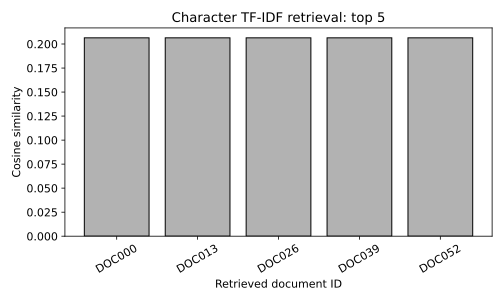

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/retrieval.svg"))

### 확인 과제

질문을 두 개 바꾸고 top-5 문서를 사람이 읽어 관련성 0/1/2점을 매겨 검색 실패 원인을 적는다.